# Эксперимент: журнал расписания

Модель Qwen3-0.6B, MLX, 4 бита, thinking выключен. Анализ читает реальные логи. Для повторения генерации используются `experiments/selection.py` и `experiments/loops.py`. Все команды запускаются из папки проекта.

In [1]:
from pathlib import Path
import os
import sys
import json

if not Path("data").exists():
    os.chdir("..")
sys.path.insert(0, str(Path.cwd()))
from experiments.analysis import analyze_selection, analyze_loops
from IPython.display import display, HTML, Image

protocol = json.loads(Path("logs/protocol.json").read_text())
print("Модель:", protocol["model"])
print("Бюджет API:", protocol["api_cost_usd"])
print("Выбор:", protocol["selection_logged"], "/ 720")
print("Петли:", protocol["loops_logged"], "/ 180")

Модель: mlx-community/Qwen3-0.6B-4bit
Бюджет API: 0
Выбор: 720 / 720
Петли: 180 / 180


## Выбор инструмента

30 запросов, 3 повтора, 4 значения N, два варианта. Точность имеет знаменатель 90 для каждой пары N/вариант. Ошибки и отсутствующие запуски считаются неверными. Бутстрэп: 10 000 выборок из запросов; три повтора одного запроса остаются вместе.

N,Вариант,Верно / 90,Точность,95% CI,Recall@5,Входные токены
5,A,63,70.0%,58.9% - 81.1%,100.0%,293.3
5,B,60,66.7%,52.2% - 80.0%,100.0%,345.3
20,A,37,41.1%,30.0% - 52.2%,53.3%,804.3
20,B,34,37.8%,22.2% - 53.3%,53.3%,322.7
50,A,11,12.2%,5.6% - 20.0%,53.3%,1885.3
50,B,23,25.6%,13.3% - 38.9%,53.3%,320.6
100,A,19,21.1%,12.2% - 31.1%,30.0%,3589.3
100,B,10,11.1%,3.3% - 21.1%,30.0%,310.0


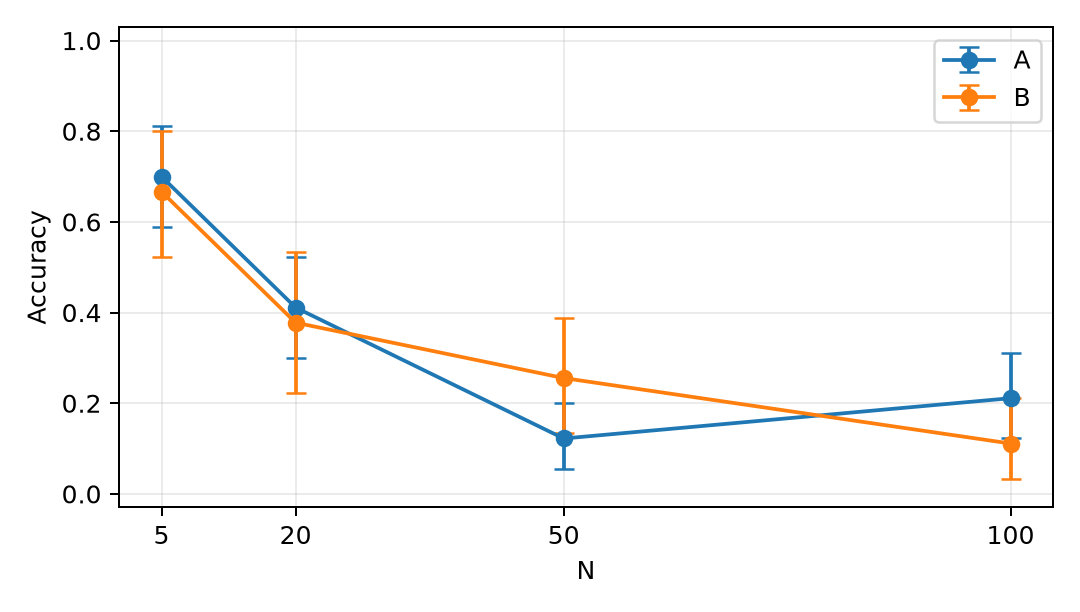

In [2]:
selection = analyze_selection()
rows = ["<tr><th>N</th><th>Вариант</th><th>Верно / 90</th><th>Точность</th><th>95% CI</th><th>Recall@5</th><th>Входные токены</th></tr>"]
for r in selection:
    rows.append(f"<tr><td>{r['n']}</td><td>{r['variant']}</td><td>{r['correct']}</td><td>{r['accuracy']:.1%}</td><td>{r['ci_low']:.1%} - {r['ci_high']:.1%}</td><td>{r['recall_at_5']:.1%}</td><td>{r['mean_input_tokens']:.1f}</td></tr>")
display(HTML("<table>" + "".join(rows) + "</table>"))
display(Image(filename="results/accuracy.png"))

## Петли

20 задач, 3 повтора, три условия, максимум 8 шагов. Успех требует правильного наблюдавшегося id. Петля: три одинаковых выполненных вызова подряд или A-B-A-B. Токены включают вход и выход всех шагов, в том числе повторную историю.

In [3]:
loops = analyze_loops()
rows = ["<tr><th>Условие</th><th>Записано / 60</th><th>Петли</th><th>Средние шаги</th><th>Средние токены</th><th>Успех</th></tr>"]
for r in loops:
    rows.append(f"<tr><td>{r['condition']}</td><td>{r['logged']}</td><td>{r['loop_rate']:.1%}</td><td>{r['mean_steps']:.2f}</td><td>{r['mean_tokens']:.1f}</td><td>{r['success_rate']:.1%}</td></tr>")
display(HTML("<table>" + "".join(rows) + "</table>"))
print("Исходная версия парсера:", protocol["parser_before_logged"], "/ 180 записанных эпизодов, успех 0/180; остальные незавершены.")
print("Она не вызывала инструменты; её логи сохранены отдельно, протокол после исправления повторён полностью.")

Условие,Записано / 60,Петли,Средние шаги,Средние токены,Успех
empty,60,66.7%,8.00,4648.1,0.0%
guard,60,60.0%,6.03,3316.3,0.0%
hint,60,51.7%,8.00,4860.8,0.0%


Исходная версия парсера: 95 / 180 записанных эпизодов, успех 0/180; остальные незавершены.
Она не вызывала инструменты; её логи сохранены отдельно, протокол после исправления повторён полностью.


## Ограничения

1. Синтетические описания и только 30 вручную размеченных запросов.
2. Одна маленькая модель, квантизация и выбор имени текстом.
3. Задачи с петлями намеренно начинаются с пустой даты, что помогает подсказке; одинаковый seed не обеспечивает одинаковые траектории после разных действий.

Выводы по фактическим метрикам приведены в PDF-отчёте.